# SRTQband Instrument Walkthrough

This notebook demonstrates how to use the AtLAST Sensitivity Calculator with the SRTQband  (INAF receiver  for SRT ) from 30 to 55  GHz receiver. The Receiver  is a 19-feed heterodyne receiver designed for the Sardinia Radio Telescope.

## SRTQband Specifications

- **Frequency Range**: 33 - 50 GHz
- **Receiver Temperature**: 
\begin{equation} 
T_{rx} \in [16K-23K] 
    \end{equation}

- **Type**: Multifeed Heterodyne receiver
- **Purpose**: High resolution spectroscopic observations
- **Instrument Webpage (in Italian)**: ["The Enhancement of the Sardinia Radio Telescope
for the Study of the Universe at High Radio Frequen
cies" financially supported by the "Programma
Operativo Nazionale"](https://sites.google.com/a/inaf.it/pon-srt/home/o-r-2?authuser=0)
- **Instrument Reference**: [Bolli et al. 2021](https://www.ursi.org/Publications/RadioScienceLetters/Volume3/RSL21-0026-final.pdf)

This walkthrough will guide you through:
1. Setting up the calculator with SRTQband parameters
2. Demonstration of the typical calculator usage
3. Ensuring correct instrument selection
4. Visualising frequency coverage
5. Evaluating atmospheric conditions
6. Calculating system performance metrics

Acknowledgement: 
The SRTQband is developent under the project "The Enhancement of the Sardinia Radio Telescope
for the Study of the Universe at High Radio Frequen
cies" financially supported by the "Programma
Operativo Nazionale"  Italian Ministry of Education,
Universities and Research "Ricerca e Innovazione
2014–2020"@" Avviso D.D. n. 424 del 28/02/2018/ per
la concessione di finanziamenti finalizzati al potenzia
mento di infrastrutture di ricerca, in attuazione dell’A
zione II.1—Proposta Progettuale PIR01_00010’

## Setup and Imports

First, we import the necessary modules and initialise the calculator.

In [1]:
# Import utilities
import numpy as np
import astropy.units as u

# Import Sensitivity Calculator
from atlast_sc.calculator import Calculator


# Import Plotting routines
import matplotlib.pyplot as plt
# Set up plotting style
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## Quick Demonstration of the Calculator Usage

Here we show a quick demonstration of how the typical user will interact with the calculator in the SRTQband parameter space.

### Initialise the Calculator with SRTQband Parameters

We'll initialise the calculator with observation parameters that fall within SRTQband's frequency range and spectral resolution capabilities. The native spectral resolution of SRTQband is 28.5 kHz, so for lower spectral resolutions, we assume smoothing.

By setting SRTQband appropriate observing frequency and spectral channel bandwidth, the AtLAST sensitivity calculator will automatically select the appropriate instrument based on the observing frequency and single channel bandwidth.

In [2]:
# Create calculator instance
calculator = Calculator()

# Set observation parameters for SRTQband
calculator.user_input.obs_freq = 40.0 * u.GHz  # within SRTQband's range (33-50  GHz)
calculator.user_input.weather = 25.0  # percentile water vapour (see documentation for conversion to mm)
calculator.user_input.bandwidth = 100.0 * u.kHz  # near the spectral resolution limit of the instrument (28.5 kHz)
calculator.user_input.t_int = 30.0 * u.min  # on source time only, no calibration time added

Instrument has been changed from Default to SRTQband.


The output above shows that, given the inputs, the code has already chosen SRTQband as a suitable instrument for this calculation. To show the full list of parameters set for the initial calculations, we can ask the calculator to 'show' the full list of inputs available. Those not explicitly set above are passed their default settings.

In [3]:
print(f"Calculator initialised with the following parameters:")
calculator.user_input.show()

Calculator initialised with the following parameters:
bandwidth: 100.0 kHz
elevation: 45.0 deg
n_pol: 2.0
obs_freq: 40.0 GHz
sensitivity: 3.0 mJy
t_int: 30.0 min
weather: 25.0


### Calculating the Sensitivity or Observing Time for an Observation

Given these inputs we can then calculate the sensitivity reached in a 30 minute observation at an observing frequency of 345 GHz and spectral resolution of 100 kHz.

In [4]:
sens = calculator.calculate_sensitivity()
print(f'RMS sensitivity per channel: {sens}')

RMS sensitivity per channel: 4.663979470788371 mJy


Alternatively we can calculate the on source observing time to reach a given sensitivity.

In [5]:
calculator.user_input.sensitivity = 24*u.mJy
obs_time = calculator.calculate_t_integration()
print(f'On source observing time required: {obs_time}')

On source observing time required: 1.1329533595799672 min


This is all that is needed for the typical user. The following steps of this notebook demonstrate the validation of the instrument and then the details of the sensitivity calculation for SRTQband.

## Ensuring Correct Instrument Selection

The calculator provides validation to ensure that your observing parameters (frequency and bandwidth) are compatible with the chosen instrument. This validation ensures your calculations are internally consistent with your expectations. If the parameters don't match, it raises an `InstrumentNotApplicableException` and suggests ways of setting a valid calculation.

### Why This Validation is Important

This validation prevents you from accidentally using an instrument with parameters outside its valid ranges, which would lead to incorrect sensitivity calculations. The error message helps you either:
- Adjust your parameters to fit the desired instrument, or
- Choose an instrument that matches your observing requirements

### Checking the Selected Instrument

Let's verify which instrument was automatically selected for our observation frequency:

In [6]:
# Check which instrument was automatically selected
print(f"Automatically selected instrument: {calculator.chosen_instrument}")

Automatically selected instrument: SRTQband


### Demonstrating Instrument Validation

Let's demonstrate how the instrument validation works. We'll first try to set SRTQbabd with incompatible parameters to see the validation in action, then show the correct approach.

In [7]:
# First, let's temporarily set incompatible parameters (bandwidth too large for SRTQband)
calculator.user_input.bandwidth = 5.0 * u.GHz  # outside SRTQbabd's range (max 180 MHz)

# This will raise an exception because our bandwidth doesn't fit SRTQband's ranges
try:
    calculator.chosen_instrument = 'SRTQband'
    print("Instrument set successfully")
except Exception as e:
    print(f"Cannot set to SRTQband: {type(e).__name__}")
    print(f"Reason: {str(e)}")

Instrument has been changed from SRTQband to Default.
Instrument name provided is not available. Proceeding with an applicable instrument from the list of instruments.
Instrument set successfully


Knowing that the setup is wrong, the above error statement is expected. Now lets reset the observing bandwidth to something that is achievable with SRTQband, and then show that that change has been applied.

In [8]:
# Reset to compatible bandwidth
calculator.user_input.bandwidth = 100.0 * u.kHz  # back within SRTQbabd's range
calculator.user_input.show()
print(f"Calculations will now be performed using: {calculator.chosen_instrument}")

Instrument has been changed from Default to SRTQband.
bandwidth: 100.0 kHz
elevation: 45.0 deg
n_pol: 2.0
obs_freq: 40.0 GHz
sensitivity: 24.0 mJy
t_int: 30.0 min
weather: 25.0
Calculations will now be performed using: SRTQband


## Visualise the inputs to the sensitivity calculation as a function of Frequency

Let's visualise how various parameters change as a function of frequency across the SRTQba bands. First, because SRTQband has a low frequency and high frequency array, lets setup an array of frequencies that combines these two ranges for derivations through the notebook

In [9]:
# Create a frequency array spanning SRTQband's specific frequency ranges for plotting
frequencies = np.linspace(33,50,10)


Because the calculator re-calculates on each parameter change, and there are a lot of calculations being done in this notebook, there is a single loop here which calculates all of the parameters we're exploring in the rest of the notebook. This includes:

* Atmospheric transmission (transmission)
* Receiver temperature (T_rx)
* System temperature (T_sys)
* Ambient temperature (T_amb)
* System Equivalent Flux Density (SEFD)
* Sensitivity

Expect this loop to take around 5 minutes.

In [10]:
# expose the SRTQband instrument module in order to pull out the temperatures used in the calculations
srtqband_instrument = calculator._param_setup.chosen_instrument

# initialise empty lists to store the calculated parameters
transmission = []
t_rx_values = []
t_sky_contribution = []
t_amb_contribution = []
sefd_values = []
sensitivity = []


# looping over the frequency ranges covered by SRTQband
for freq in frequencies:
    # Set the observing frequency for this loop iteration, which triggers a re-calculation
    calculator.user_input.obs_freq = freq * u.GHz

    # extract atmospheric transmission from the calculator, and add it to the list
    transmission.append(calculator.derived_parameters.transmittance)

    # extract receiver temperature from the calculator, and add it to the list
    t_rx = srtqband_instrument.calculate_receiver_temp(calculator.user_input.obs_freq)
    t_rx_values.append(t_rx)

    # extract sky and ambient temperatures from the calculator, and add them to the lists
    t_sky_contribution.append(calculator.derived_parameters.T_sky.value)
    t_amb_contribution.append(calculator.telescope_and_environment.T_amb.value)

    # extract SEFD from the calculator, and add it to the list
    sefd_values.append(calculator.derived_parameters.sefd.to("Jy").value)

    # extract sensitivity from the calculator, and add it to the list
    sensitivity.append(calculator.calculate_sensitivity())

With all of those parameters derived, the following describes how they're used in the calculator, and we plot their values over the operational frequency ranges of SRTQband.

### Atmospheric Transmission

To show how atmospheric transmission varies, we plot the transmission as a function of frequency across the SRTQband operational frequency ranges. This is important for understanding how the sensitivity of the instrument changes with frequency.  The atmospheric transmission is calculated using the am code.

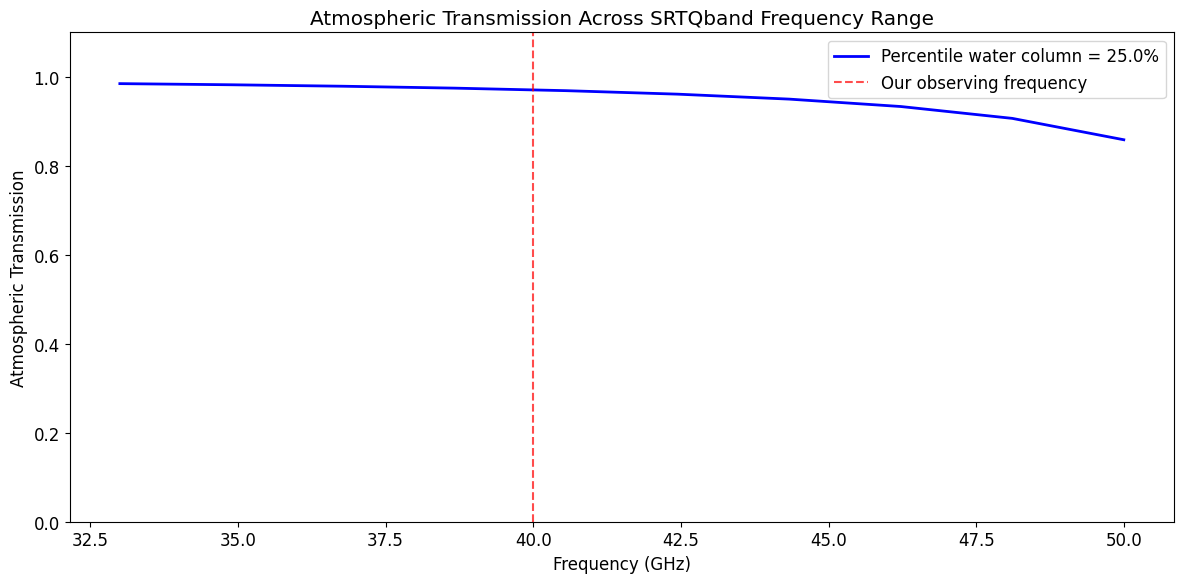

In [12]:
# Reset to our primary observing frequency
calculator.user_input.obs_freq = 40*u.GHz

# Plot
fig, ax = plt.subplots()

# plot atmospheric transmission over the SRTQband operational frequency ranges
ax.plot(frequencies, transmission, 'b-', linewidth=2, label=f'Percentile water column = {calculator.user_input.weather}%')
# draw a vertical line at our observing frequency (dashed)
ax.axvline(calculator.user_input.obs_freq.value, color='r', linestyle='--', alpha=0.7, label='Our observing frequency')


# label the plot
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Atmospheric Transmission')
ax.set_title('Atmospheric Transmission Across SRTQband Frequency Range')
ax.legend()
ax.set_ylim([0, 1.1])
plt.tight_layout()
plt.show()

## Receiver Temperature Calculation

SRTQband's receiver temperature changes between the two arrays, as shown below.

* T_rx  linearly interpolate from 16 K at 33 GHz to 23 K at 50 GHz.

We can show how the receiver temperatures are set for the two arrays, which is important for understanding the sensitivity of the instrument. The receiver temperature is a key factor in determining the instrument's sensitivity, as it affects the amount of noise that is added to the signal.

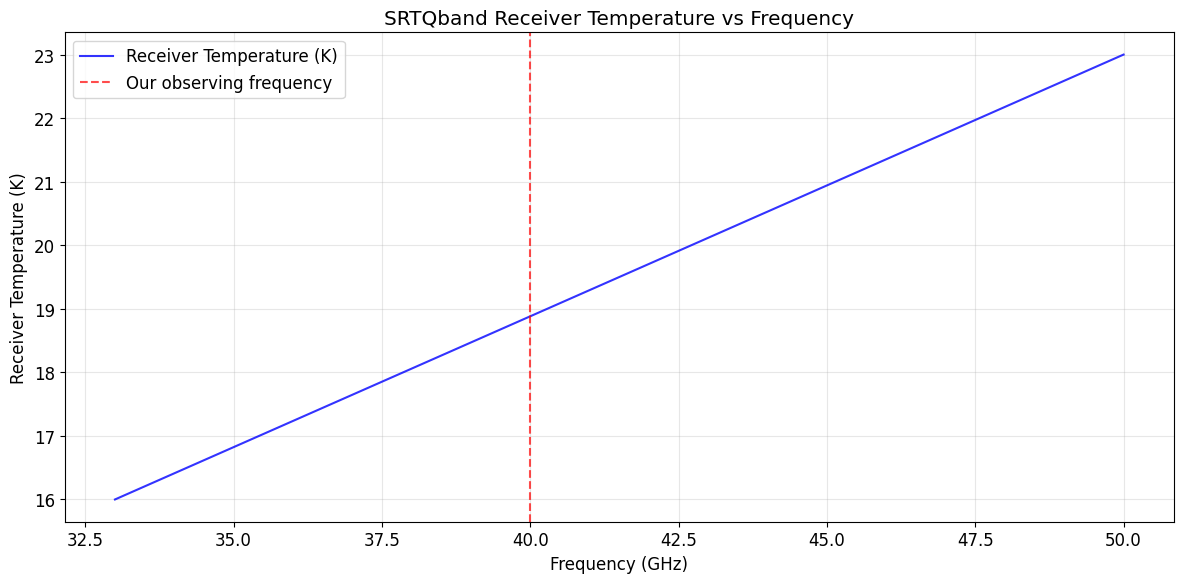

In [13]:
# Filter out None values from t_rx_values for plotting
valid_data = [(freq, t_rx) for freq, t_rx in zip(frequencies, t_rx_values) if t_rx is not None]
valid_frequencies, valid_t_rx = zip(*valid_data) if valid_data else ([], [])

# Plot the receiver temperatures.
fig, ax = plt.subplots()
ax.plot(valid_frequencies, [t.value for t in valid_t_rx], '-',label = 'Receiver Temperature (K)', color='b', markersize=10, alpha=0.8)

# label the plot
ax.axvline(calculator.user_input.obs_freq.value, color='r', linestyle='--', alpha=0.7, label='Our observing frequency')

ax.legend()
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Receiver Temperature (K)')
ax.set_title('SRTQband Receiver Temperature vs Frequency')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## System Temperature Calculation

The instrument module calculates the system temperature using the following equation:

$$    T_{sys} = \frac{1}{\eta_{eff} \mathfrak{t}} \times [T_{rx} + (\eta_{eff} T_{sky}) + (1-\eta_{eff}) O(\nu, T_\mathrm{amb})]$$


It includes contributions from:
- Receiver temperature (T_rx)
- Sky temperature (T_sky)
- Ambient Temperature (T_amb)

Here, $O(\nu, T)$ is the conversion from a thermodynamic temperature to a Rayleigh-Jeans brightness temperature that is applied to the ambient temperature for consistency with the receiver temperature and sky temperature

\begin{equation}
    O(\nu, T) = T \frac{h\nu/kT}{\exp(h\nu/kT)-1}.  \nonumber
\end{equation}
where $h$ and $k$ are the Planck and Boltzmann constants respectively.

Below, we show plots of the three noise temperature equivalent components of the system temperature: sky, ambient and receiver as a function of frequency.

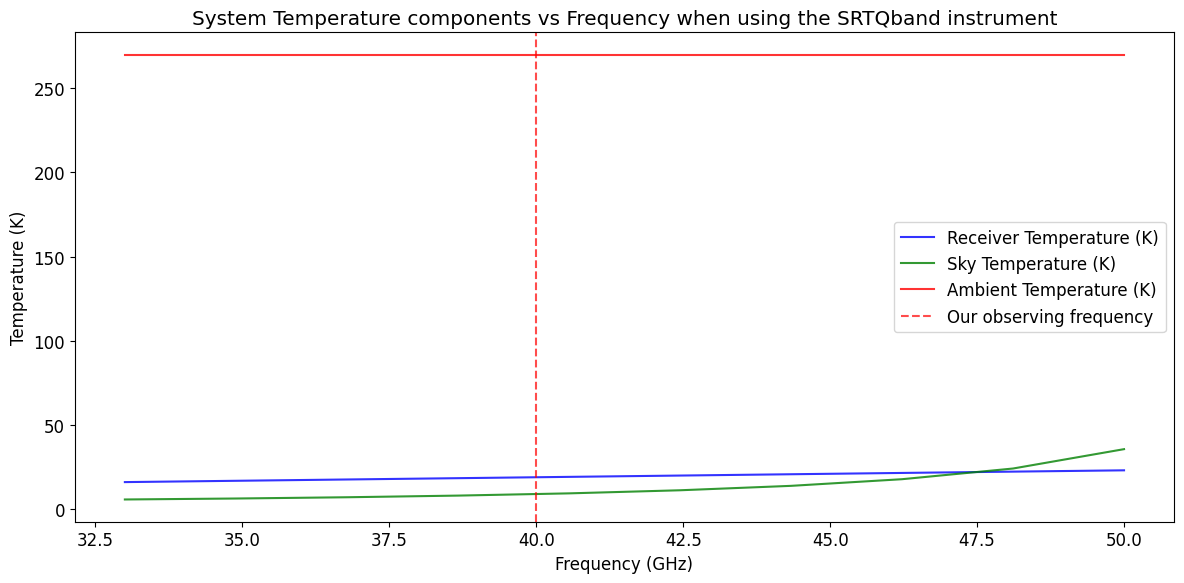

In [14]:
fig, ax = plt.subplots()
ax.plot(valid_frequencies, [t.value for t in valid_t_rx], '-',label = 'Receiver Temperature (K)', color='b', markersize=10, alpha=0.8)
ax.plot(frequencies, t_sky_contribution, '-',label = 'Sky Temperature (K)', color='g', markersize=10, alpha=0.8)
ax.plot(frequencies, t_amb_contribution, '-',label = 'Ambient Temperature (K)', color='r', markersize=10, alpha=0.8)

# label the plot
ax.axvline(calculator.user_input.obs_freq.value, color='r', linestyle='--', alpha=0.7, label='Our observing frequency')

ax.legend()
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Temperature (K)')
ax.set_title('System Temperature components vs Frequency when using the SRTQband instrument')

plt.tight_layout()
plt.show()

## SEFD Calculation

The System Equivalent Flux Density (SEFD) characterises the sensitivity of the telescope system. The system temperature derived in the instrument module is used to calculate the overall SEFD for the telescope, which is then used to calculate the sensitivity.

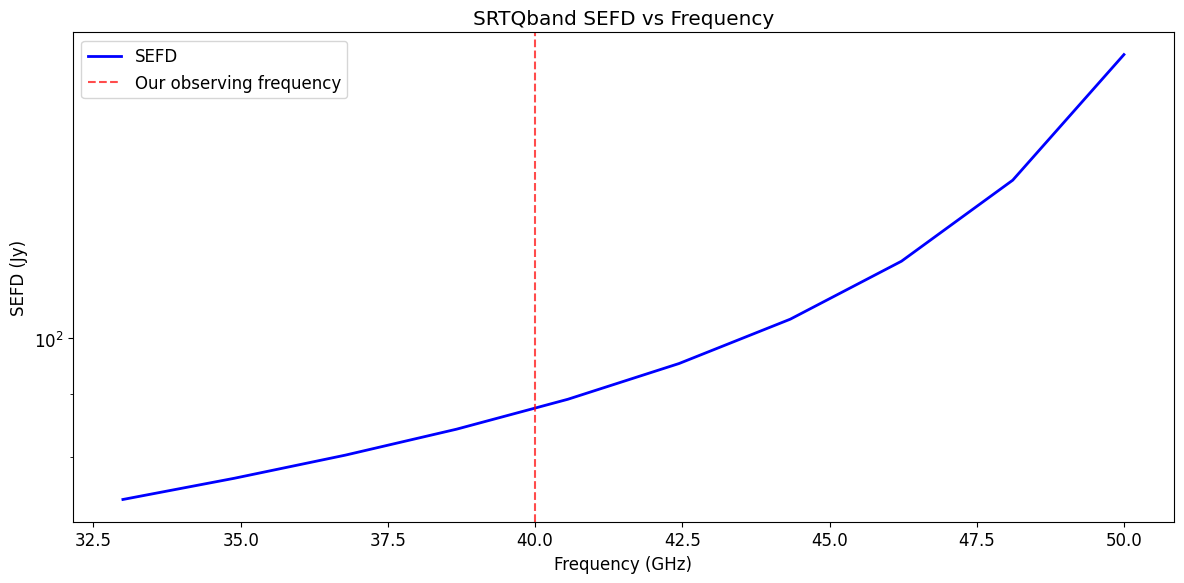

In [15]:
# Plot SEFD as a function of frequency
fig, ax = plt.subplots()
ax.plot(frequencies, sefd_values, 'b-', linewidth=2, label='SEFD')

# label the plot
ax.axvline(calculator.user_input.obs_freq.value, color='r', linestyle='--', alpha=0.7, label='Our observing frequency')

ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('SEFD (Jy)')
ax.set_yscale('log')
ax.set_title('SRTQband SEFD vs Frequency')

ax.legend()
plt.tight_layout()
plt.show()

## Sensitivity Calculation

With all of those underlying values calculated and plotted, now let's calculate the RMS sensitivity of the telescope when using the SRTQband instrument.

Sensitivity for an integration time of 30.0 min


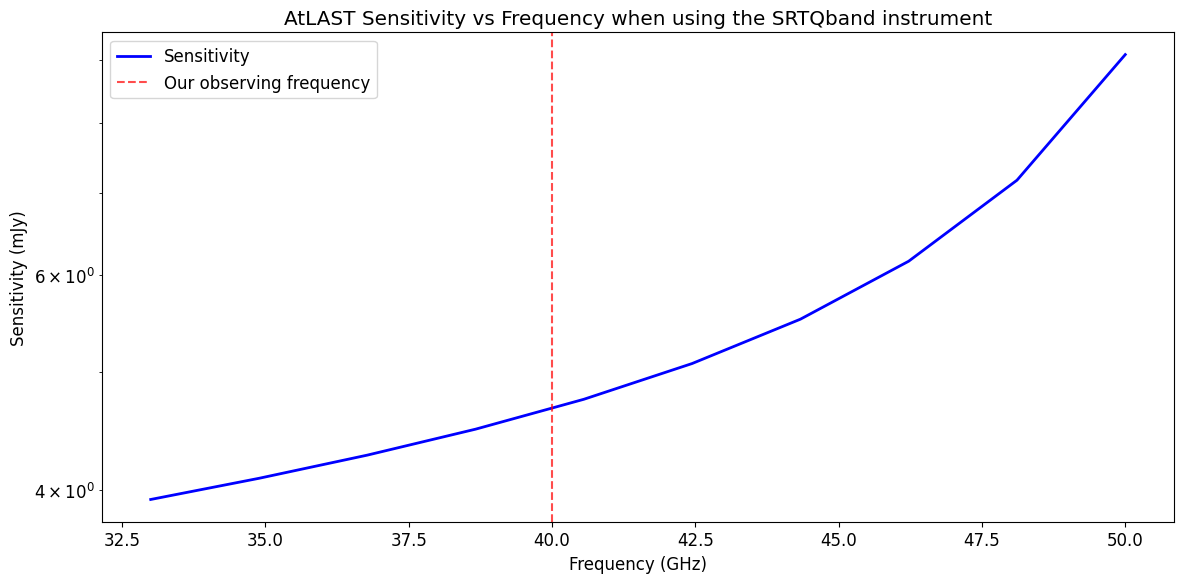

In [16]:
# Remind ourselves of the integration time used for this calculation
print(f"Sensitivity for an integration time of {calculator.user_input.t_int}")

# Show calculated sensitivity
fig, ax = plt.subplots()
# extract the astropy quantity sensitivities from the sensitivity array calculated above
ax.plot(frequencies, [q.to("mJy").value for q in sensitivity], 'b-', linewidth=2, label='Sensitivity')

# label the plot
ax.axvline(calculator.user_input.obs_freq.value, color='r', linestyle='--', alpha=0.7, label='Our observing frequency')

ax.set_yscale('log')
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Sensitivity (mJy)')
ax.set_title('AtLAST Sensitivity vs Frequency when using the SRTQband instrument')

ax.legend()
plt.tight_layout()
plt.show()

## Summary

This notebook has demonstrated the key capabilities of the AtLAST Sensitivity Calculator for the SRTQband instrument:

1. **Instrument Selection**: Verified automatic selection and demonstrated explicit instrument setting
2. **Frequency Coverage**: Explored SRTQband's 33-50 GHz range
3. **Atmospheric Effects**: Analysed transmission and emission across the SRTQband operating frequency ranges
4. **System Performance**: Calculated system temperature, its components, and the overall SEFD
5. **Sensitivity Predictions**: Evaluated spectral line sensitivities across the SRTQband frequency range